### Full Factorial Design

First steps in DOE

In [1]:
# Dependencies
import matplotlib.pyplot as plt
import numpy as np

# Settings
np.set_printoptions(precision=3)

# Helper Functions
def measure_response(x_1, x_2, noise=True):
    a =  0.5  # 0.3, -1.0
    b = -0.5  # 0.7,  0.2
    c =  2.0  # 1.0, -1.5
    y_1 = a*x_1 + b*x_2 + c*x_1*x_2
    y_1 += noise * np.random.normal(0, 0.2, y_1.shape)
    return y_1

<Figure size 640x480 with 0 Axes>

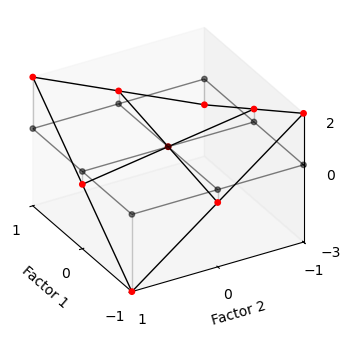

In [2]:
num = 3
x1 = np.linspace(-1,1,num=num)
x2 = np.linspace(-1,1,num=num)
x1_, x2_ = np.meshgrid(x1, x2)

y1 = measure_response(x1_, x2_, False)

plt.clf()

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks([-1,0,1])
ax.set_yticks([-1,0,1])
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel('Factor 1')
ax.set_ylabel('Factor 2')
ax.set_zlabel('Response')
ax.plot_wireframe(x1_, x2_, y1*0, linewidth=1, color='k', alpha=0.5)
ax.scatter(x1_, x2_, y1*0, s=15, color='k', alpha=0.5)
ax.plot_wireframe(x1_, x2_, y1, linewidth=1, color='k')
ax.scatter(x1_, x2_, y1, s=15, color='r', alpha=1)

for xi, yi, zi in zip(x1_.flatten(), x2_.flatten(), y1.flatten()):
    ax.plot([xi, xi], [yi, yi], [0, zi], color='k', alpha=0.2, linewidth=1)

plt.show()

In [3]:
""" Understanding OFAT vs Full Factor """
# OFAT design
x1m_ofat = np.array([0,  0, 0, -1, 1])
x2m_ofat = np.array([0, -1, 1,  0, 0])
y1m_ofat = measure_response(x1m_ofat, x2m_ofat)
print("OFAT\n", np.c_[x1m_ofat, x2m_ofat, y1m_ofat], "\n")

# Full Factor design
x1m_ff = np.array([0, 0,  0, 1, 1,  1, -1, -1, -1])
x2m_ff = np.array([0, 1, -1, 0, 1, -1,  0,  1, -1])
y1m_ff = measure_response(x1m_ff, x2m_ff)
print("Full Factorial\n", np.c_[x1m_ff, x2m_ff, y1m_ff])

OFAT
 [[ 0.     0.     0.106]
 [ 0.    -1.     0.232]
 [ 0.     1.    -0.374]
 [-1.     0.    -0.457]
 [ 1.     0.     0.632]] 

Full Factorial
 [[ 0.     0.    -0.269]
 [ 0.     1.    -0.207]
 [ 0.    -1.     0.525]
 [ 1.     0.     0.62 ]
 [ 1.     1.     2.015]
 [ 1.    -1.    -0.825]
 [-1.     0.    -0.481]
 [-1.     1.    -2.947]
 [-1.    -1.     2.068]]


<Figure size 640x480 with 0 Axes>

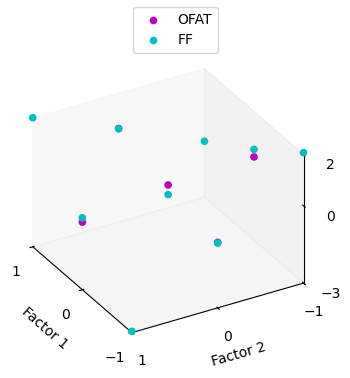

In [4]:
plt.clf()

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks([-1,0,1])
ax.set_yticks([-1,0,1])
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel('Factor 1')
ax.set_ylabel('Factor 2')
ax.set_zlabel('Response')
ax.scatter(x1m_ofat, x2m_ofat, y1m_ofat, color='m', alpha=1, label='OFAT')
ax.scatter(x1m_ff, x2m_ff, y1m_ff, color='c', alpha=1, label='FF')
fig.legend(loc='upper center')

plt.show()

β0: 0.0555
β1 (x): 0.5282
β2 (y): -0.4846
β3 (xy): 1.9640


<Figure size 640x480 with 0 Axes>

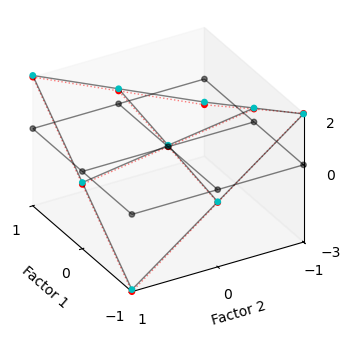

In [5]:
""" Model regression from measured data """
from sklearn.linear_model import LinearRegression

x1m = x1m_ff
x2m = x2m_ff
y1m = y1m_ff

# Design matrix for second-order model
X = np.column_stack((np.ones(x1m.shape),  # intercept
                     x1m,
                     x2m,
                     x1m*x2m))

# Fit regression
model = LinearRegression(fit_intercept=False)  # intercept already in X
model.fit(X, y1m)
betas = model.coef_

# Output coefficients
coeff_labels = ['β0', 'β1 (x)', 'β2 (y)', 'β3 (xy)']
for label, coef in zip(coeff_labels, betas):
    print(f'{label}: {coef:.4f}')

x1m_grid, x2m_grid = np.meshgrid(np.unique(x1m), np.unique(x2m))
y1m_grid = (betas[0] +
            betas[1]*x1m_grid +
            betas[2]*x2m_grid +
            betas[3]*x1m_grid*x2m_grid)

plt.clf()

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(1,1,1,projection='3d')
ax.set_proj_type('ortho')
ax.view_init(30, 150)
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)
ax.set_zlim(np.min(y1),np.max(y1))
ax.set_xticks([-1,0,1])
ax.set_yticks([-1,0,1])
ax.set_zticks([np.min(y1),0,np.max(y1)])
ax.grid(False)
ax.set_xlabel('Factor 1')
ax.set_ylabel('Factor 2')
ax.set_zlabel('Response')
ax.scatter(x1_, x2_, y1, s=15, color='r', alpha=1)
ax.plot_wireframe(x1_, x2_, y1, linestyle=':', linewidth=1, color='r', alpha=0.5)
ax.plot_wireframe(x1m_grid, x2m_grid, y1m_grid*0, linewidth=1, color='k', alpha=0.5)
ax.scatter(x1m_grid, x2m_grid, y1m_grid*0, s=15, color='k', alpha=0.5)
ax.plot_wireframe(x1m_grid, x2m_grid, y1m_grid, linewidth=1, color='k', alpha=0.5)
ax.scatter(x1m_grid, x2m_grid, y1m_grid, s=15, color='c', alpha=1)

plt.show()

#### Toy Example
Let's better understand how to DOE

#### Industrial Example: Machining

Response: Roughness

Table of factors

|Symbol|Factor|Level 1|Level 2|Level 3|
|---|---|---|---|---|
|MEU|Kind of grindstone|1|2| |
|ROT|Rotation of the part|4|6|8|
|VIT|Grindstone speed|6000|6500| |

Measured data

|MEU|ROT|VIT|Roughness|
|---|---|---|---|
|M1|4|6000|0.36|
|M1|4|6500|0.47|
|M1|6|6000|0.39|
|M1|6|6500|0.53|
|M1|8|6000|0.46|
|M1|8|6500|0.74|
|M2|4|6000|0.37|
|M2|4|6500|0.49|
|M2|6|6000|0.41|
|M2|6|6500|0.55|
|M2|8|6000|0.48|
|M2|8|6500|0.76|

In [6]:
import pandas as pd

# Factor levels
A_levels = np.array([1, 2])        # 2 levels
B_levels = np.array([4, 6, 8])     # 3 levels
C_levels = np.array([6000, 6500])  # 2 levels

# Number of levels per factor
n_A = len(A_levels)
n_B = len(B_levels)
n_C = len(C_levels)

# Total runs
n_runs = n_A * n_B * n_C

# Create the design matrix columns
# For A: repeat each level for (n_B*n_C) times, then tile for n_A times
A = np.repeat(A_levels, n_B * n_C)

# For B: repeat each level for n_C times, tile for n_A times
B = np.tile(np.repeat(B_levels, n_C), n_A)

# For C: tile levels for (n_A * n_B) times
C = np.tile(C_levels, n_A * n_B)

# Stack columns into a design matrix
design = np.array([A, B, C]).T
# design = np.c_[A.T, B.T, C.T]
# design = np.r_[[A], [B], [C]].T
# design = np.r_[A, B, C].reshape((3,-1)).T
# design = np.r_[A, B, C].T.reshape((-1,3))

# Convert to DataFrame for readability
df = pd.DataFrame(design, columns=['A', 'B', 'C'])
display(df)

,A,B,C
0,1,4,6000
1,1,4,6500
2,1,6,6000
3,1,6,6500
4,1,8,6000
5,1,8,6500
6,2,4,6000
7,2,4,6500
8,2,6,6000
9,2,6,6500


In [7]:
# Define true effects (arbitrary example)
# def simulate_response(A, B, C):
#     """
#     y = intercept + A_effect + B_effect + C_effect + interactions + noise
#     """
#     return (5                      # intercept
#             + 2 * A                # effect of A
#             + 3 * B                # effect of B
#             - 1.5 * C              # effect of C
#             + 1.2 * A * B          # interaction A*B
#             + 0.5 * B * C          # interaction B*C
#             + np.random.normal(0, 0.5))  # noise

# Apply function row-wise
# df['y'] = [simulate_response(a, b, c) for a, b, c in design]

# Output from data (manually)
df['y'] = np.array([0.36, 0.47, 0.39, 0.53, 0.46, 0.74, 0.37, 0.49, 0.41, 0.55, 0.48, 0.76])
display(df)

,A,B,C,y
0,1,4,6000,0.36
1,1,4,6500,0.47
2,1,6,6000,0.39
3,1,6,6500,0.53
4,1,8,6000,0.46
5,1,8,6500,0.74
6,2,4,6000,0.37
7,2,4,6500,0.49
8,2,6,6000,0.41
9,2,6,6500,0.55


In [8]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Convert numeric factors to categorical strings (IMPORTANT!)
df['A_cat'] = pd.Categorical(df['A'].astype(str))

# Check for NaNs and infs in response and factors
print(df.isna().sum())
print(np.isfinite(df['y']).all())

# Fit model with all interactions using categorical variables
model = ols('y ~ A_cat + B + C + A_cat:B + B:C + A_cat:C', data=df).fit()
print(model.params)

# Perform an ANOVA (analysis of variance) (type II sums of squares)
anova_table = sm.stats.anova_lm(model, typ=2)
display(anova_table)

A        0
B        0
C        0
y        0
A_cat    0
dtype: int64
True
Intercept       1.099583
A_cat[T.2]     -0.030833
B              -0.469375
A_cat[T.2]:B    0.001250
C              -0.000142
A_cat[T.2]:C    0.000007
B:C             0.000083
dtype: float64


,sum_sq,df,F,PR(>F)
A_cat,0.001008,1.0,0.635838,0.461394
B,0.070312,1.0,44.337888,0.001153
A_cat:B,0.000013,1.0,0.007882,0.932701
C,0.095408,1.0,60.162901,0.000570
A_cat:C,0.000008,1.0,0.005255,0.945022
B:C,0.013612,1.0,8.583815,0.032640
Residual,0.007929,5.0,NaN,NaN


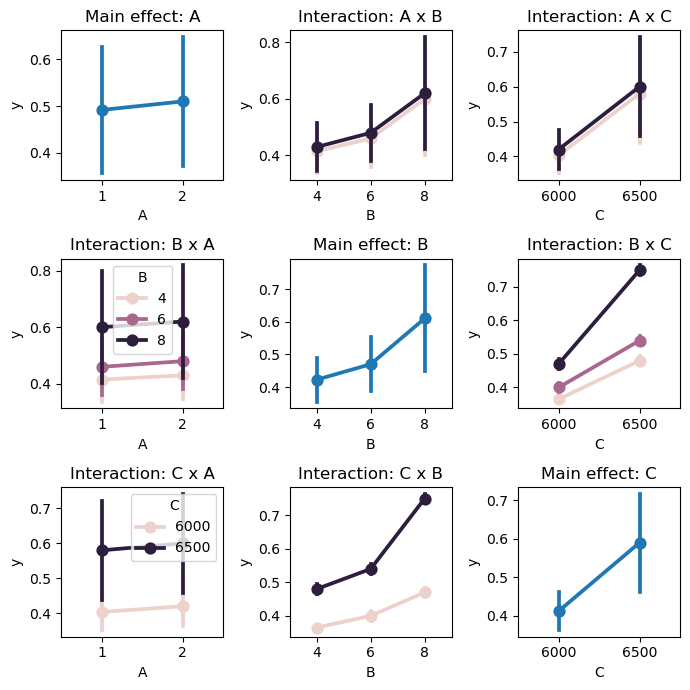

In [9]:
import seaborn as sns

factors = ['A', 'B', 'C']
response = 'y'

# Set up subplot grid size (main effects + pairwise interactions)
n = len(factors)
fig, axes = plt.subplots(n, n, figsize=(7, 7), sharey=False)

for i, f1 in enumerate(factors):
    for j, f2 in enumerate(factors):
        ax = axes[i, j]
        if i == j:
            # Main effect plot: factor f1 on x-axis
            sns.pointplot(x=f1, y=response, data=df, errorbar='sd', ax=ax)
            ax.set_title(f'Main effect: {f1}')
            ax.set_xlabel(f1)
            ax.set_ylabel(response)
        else:
            # Interaction plot: f2 on x-axis, f1 as hue
            sns.pointplot(x=f2, y=response, hue=f1, data=df, errorbar='sd', ax=ax)
            ax.set_title(f'Interaction: {f1} x {f2}')
            ax.set_xlabel(f2)
            ax.set_ylabel(response)
            if j == 0:
                ax.legend(title=f1)
            else:
                ax.get_legend().remove()

plt.tight_layout()
plt.show()